In [1]:
# !pip install ta 

In [1]:
#impotrs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# import seaborn as sns

import ta

# import yfinance as yf 

# Предобработка данных

In [2]:
df = pd.read_csv('AAPL.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

print("Форма:", df.shape)
print()
print(df.head())
print()
print(df.dtypes)

Форма: (10409, 7)

        Date      Open      High       Low     Close  Adj Close     Volume
0 1980-12-12  0.128348  0.128906  0.128348  0.128348   0.100323  469033600
1 1980-12-15  0.122210  0.122210  0.121652  0.121652   0.095089  175884800
2 1980-12-16  0.113281  0.113281  0.112723  0.112723   0.088110  105728000
3 1980-12-17  0.115513  0.116071  0.115513  0.115513   0.090291   86441600
4 1980-12-18  0.118862  0.119420  0.118862  0.118862   0.092908   73449600

Date         datetime64[ns]
Open                float64
High                float64
Low                 float64
Close               float64
Adj Close           float64
Volume                int64
dtype: object


In [3]:
# Дневная доходность
df['Return'] = df['Close'].pct_change()

# Логарифмическая доходность
df['Log_Return'] = np.log(df['Close'] / df['Close'].shift(1))

# Скользящие средние
df['SMA_10'] = df['Close'].rolling(window=10).mean()
df['SMA_20'] = df['Close'].rolling(window=20).mean()
df['SMA_50'] = df['Close'].rolling(window=50).mean()

# Экспоненциальное скользящее среднее
df['EMA_20'] = df['Close'].ewm(span=20, adjust=False).mean()

# Волатильность
df['Volatility_20'] = df['Return'].rolling(window=20).std()

# Расстояние цены от SMA_20
df['Close_vs_SMA20'] = (df['Close'] - df['SMA_20']) / df['SMA_20']

print(df[['Return', 'Log_Return', 'SMA_20', 'EMA_20', 'Volatility_20']].head(25))

      Return  Log_Return    SMA_20    EMA_20  Volatility_20
0        NaN         NaN       NaN  0.128348            NaN
1  -0.052171   -0.053581       NaN  0.127710            NaN
2  -0.073398   -0.076231       NaN  0.126283            NaN
3   0.024751    0.024450       NaN  0.125257            NaN
4   0.028992    0.028580       NaN  0.124648            NaN
5   0.061029    0.059239       NaN  0.124788            NaN
6   0.048669    0.047522       NaN  0.125499            NaN
7   0.042199    0.041333       NaN  0.126674            NaN
8   0.052628    0.051290       NaN  0.128428            NaN
9   0.092309    0.088294       NaN  0.131290            NaN
10  0.014084    0.013985       NaN  0.134092            NaN
11 -0.024304   -0.024604       NaN  0.136256            NaN
12 -0.028468   -0.028881       NaN  0.137788            NaN
13  0.010988    0.010928       NaN  0.139334            NaN
14 -0.021738   -0.021977       NaN  0.140413            NaN
15 -0.044448   -0.045466       NaN  0.14

In [4]:
# Добавляем День недели и месяц
df['Day_of_Week'] = df['Date'].dt.day_name()
df['Month'] = df['Date'].dt.month_name()

print(df[['Date', 'Day_of_Week', 'Month']].head(10))
print()
print(df['Day_of_Week'].value_counts())
print()
print(df['Month'].value_counts())

        Date Day_of_Week     Month
0 1980-12-12      Friday  December
1 1980-12-15      Monday  December
2 1980-12-16     Tuesday  December
3 1980-12-17   Wednesday  December
4 1980-12-18    Thursday  December
5 1980-12-19      Friday  December
6 1980-12-22      Monday  December
7 1980-12-23     Tuesday  December
8 1980-12-24   Wednesday  December
9 1980-12-26      Friday  December

Day_of_Week
Tuesday      2134
Wednesday    2133
Thursday     2094
Friday       2078
Monday       1970
Name: count, dtype: int64

Month
March        916
August       907
October      905
December     880
June         878
July         868
January      866
May          865
April        848
November     838
September    833
February     805
Name: count, dtype: int64


In [5]:
# Удаляем NaN
print("До очистки:", df.shape)
df = df.dropna().reset_index(drop=True)
print("После очистки:", df.shape)
# потеряли 49, переживем)))

До очистки: (10409, 17)
После очистки: (10360, 17)


In [6]:
# проверка
print("Форма:", df.shape)
print()
print("Столбцы:", df.columns.tolist())
print()
print("Пропусков:", df.isna().sum().sum())
print()
df.describe().round(3)

Форма: (10360, 17)

Столбцы: ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Return', 'Log_Return', 'SMA_10', 'SMA_20', 'SMA_50', 'EMA_20', 'Volatility_20', 'Close_vs_SMA20', 'Day_of_Week', 'Month']

Пропусков: 0



,Date,Open,High,Low,Close,Adj Close,Volume,Return,Log_Return,SMA_10,SMA_20,SMA_50,EMA_20,Volatility_20,Close_vs_SMA20
count,10360,10360.000,10360.000,10360.000,10360.000,10360.000,1.036000e+04,10360.000,10360.000,10360.000,10360.000,10360.000,10360.000,10360.000,10360.000
mean,2001-08-30 22:09:13.204633216,14.025,14.178,13.874,14.032,13.413,3.335353e+08,0.001,0.001,13.960,13.883,13.643,13.882,0.025,0.008
min,1981-02-24 00:00:00,0.050,0.050,0.049,0.049,0.038,0.000000e+00,-0.519,-0.731,0.053,0.056,0.058,0.056,0.005,-0.569
25%,1991-05-21 18:00:00,0.286,0.292,0.279,0.286,0.238,1.259524e+08,-0.013,-0.013,0.286,0.286,0.286,0.285,0.017,-0.031
50%,2001-08-21 12:00:00,0.473,0.482,0.464,0.475,0.391,2.216474e+08,0.000,0.000,0.472,0.468,0.464,0.465,0.023,0.009
75%,2011-12-07 06:00:00,14.325,14.489,14.163,14.354,12.327,4.144888e+08,0.015,0.015,14.321,14.126,14.013,14.208,0.031,0.048
max,2022-03-24 00:00:00,182.630,182.940,179.120,182.010,181.778,7.421641e+09,0.332,0.287,178.332,176.396,172.664,174.826,0.129,0.617
std,NaN,30.225,30.572,29.891,30.248,29.968,3.395278e+08,0.028,0.029,30.071,29.892,29.298,29.876,0.013,0.070


In [7]:
print("Датасет подготовлен:", df.shape)

Датасет подготовлен: (10360, 17)


In [8]:
df['Target'] = (df['Close'].shift(-1) > df['Close']).astype(int)
print(df['Target'].value_counts())

Target
0    5222
1    5138
Name: count, dtype: int64


In [9]:
df = df.dropna().reset_index(drop=True)
print("После финальной очистки:", df.shape)

После финальной очистки: (10360, 18)


In [10]:
# удаляем ложный таргет
df = df.iloc[:-1].reset_index(drop=True)
print("После удаления последней строки:", df.shape)

После удаления последней строки: (10359, 18)


In [11]:
# Добавляем признаки дат квартальных и годовых отчетов Apple
report_dates = pd.read_csv('report-dates.csv')

df['Date'] = pd.to_datetime(df['Date']).dt.date
report_dates['Filing date'] = pd.to_datetime(report_dates['Filing date']).dt.date

report_quarter_dates = set(report_dates['Filing date'])
report_year_dates = set(
    report_dates.loc[report_dates['Form type'].eq('10-K'), 'Filing date']
)

df['report_quarter'] = df['Date'].isin(report_quarter_dates)
df['report_year'] = df['Date'].isin(report_year_dates)

df['Date'] = pd.to_datetime(df['Date']).dt.strftime('%Y-%m-%d')

print('report_quarter=True:', df['report_quarter'].sum())
print('report_year=True:', df['report_year'].sum())

df.to_csv('AAPL_features.csv', index=False)
print('Сохранено:', df.shape)
df.head()

report_quarter=True: 114
report_year=True: 26
Сохранено: (10359, 20)


,Date,Open,High,Low,Close,Adj Close,Volume,Return,Log_Return,SMA_10,SMA_20,SMA_50,EMA_20,Volatility_20,Close_vs_SMA20,Day_of_Week,Month,Target,report_quarter,report_year
0,1981-02-24,0.107143,0.107143,0.106027,0.106027,0.082876,16979200,-0.035531,-0.036177,0.114676,0.121763,0.132578,0.120632,0.033942,-0.129238,Tuesday,February,1,False,False
1,1981-02-25,0.112723,0.113281,0.112723,0.112723,0.088110,19488000,0.063154,0.061240,0.113783,0.120257,0.132266,0.119878,0.038141,-0.062647,Wednesday,February,1,False,False
2,1981-02-26,0.114397,0.114955,0.114397,0.114397,0.089418,10841600,0.014851,0.014741,0.113448,0.119057,0.132121,0.119356,0.038251,-0.039140,Thursday,February,1,False,False
3,1981-02-27,0.118304,0.119420,0.118304,0.118304,0.092472,14761600,0.034153,0.033583,0.113616,0.118304,0.132232,0.119256,0.038823,0.000004,Friday,February,1,False,False
4,1981-03-02,0.118862,0.119420,0.118862,0.118862,0.092908,11760000,0.004717,0.004706,0.114118,0.117941,0.132299,0.119219,0.037097,0.007810,Monday,March,0,False,False


## Постановка задачи регрессии следующего бара

Теперь решаем задачу multi-output regression: по информации на день `t` прогнозируем логарифмические доходности следующего дневного бара Apple (`AAPL`) на день `t+1` относительно текущего `Close`.

Целевые переменные:

- `Next_Open_Log_Return = log(Next_Open / Close)`
- `Next_High_Log_Return = log(Next_High / Close)`
- `Next_Low_Log_Return = log(Next_Low / Close)`
- `Next_Close_Log_Return = log(Next_Close / Close)`

Это более корректная финансовая постановка, чем прогноз абсолютных цен: модель учится прогнозировать относительное изменение цены, а не уровень цены. Старый бинарный `Target` для направления движения дальше не используем как признак и не используем как целевую переменную.

## Подготовка регрессионных таргетов

Загружаем финальный датасет `AAPL_features.csv`, сортируем его по дате и создаем таргеты логарифмической доходности следующего бара через `shift(-1)`. Последняя строка удаляется, потому что для нее неизвестен следующий бар.

При моделировании важно не использовать будущую информацию. Поэтому признаки берутся из строки текущего дня, а целевые значения — из следующего дня. Абсолютные цены следующего бара сохраняются только для обратного восстановления цены, расчета IoU и построения графиков.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Загружаем финальный датасет, чтобы моделирующий раздел можно было запускать независимо
reg_df = pd.read_csv('AAPL_features.csv')
reg_df['Date'] = pd.to_datetime(reg_df['Date'])
reg_df = reg_df.sort_values('Date').reset_index(drop=True)

current_ohlc_cols = ['Open', 'High', 'Low', 'Close']
next_price_cols = ['Next_Open_Price', 'Next_High_Price', 'Next_Low_Price', 'Next_Close_Price']
target_cols = ['Next_Open_Log_Return', 'Next_High_Log_Return', 'Next_Low_Log_Return', 'Next_Close_Log_Return']

for current_col, next_price_col, target_col in zip(current_ohlc_cols, next_price_cols, target_cols):
    reg_df[next_price_col] = reg_df[current_col].shift(-1)
    reg_df[target_col] = np.log(reg_df[next_price_col] / reg_df['Close'])

reg_df = reg_df.dropna(subset=next_price_cols + target_cols).reset_index(drop=True)

print('Размер датасета для регрессии:', reg_df.shape)
print('Период:', reg_df['Date'].min().date(), '-', reg_df['Date'].max().date())
print('Количество пропусков:', reg_df.isna().sum().sum())

display(reg_df.head())
display(reg_df[target_cols].describe())

Размер датасета для регрессии: (10358, 28)
Период: 1981-02-24 - 2022-03-22
Количество пропусков: 0


,Date,Open,High,Low,Close,Adj Close,Volume,Return,Log_Return,SMA_10,...,report_quarter,report_year,Next_Open_Price,Next_Open_Log_Return,Next_High_Price,Next_High_Log_Return,Next_Low_Price,Next_Low_Log_Return,Next_Close_Price,Next_Close_Log_Return
0,1981-02-24,0.107143,0.107143,0.106027,0.106027,0.082876,16979200,-0.035531,-0.036177,0.114676,...,False,False,0.112723,0.061240,0.113281,0.066178,0.112723,0.061240,0.112723,0.061240
1,1981-02-25,0.112723,0.113281,0.112723,0.112723,0.088110,19488000,0.063154,0.061240,0.113783,...,False,False,0.114397,0.014741,0.114955,0.019607,0.114397,0.014741,0.114397,0.014741
2,1981-02-26,0.114397,0.114955,0.114397,0.114397,0.089418,10841600,0.014851,0.014741,0.113448,...,False,False,0.118304,0.033583,0.119420,0.042972,0.118304,0.033583,0.118304,0.033583
3,1981-02-27,0.118304,0.119420,0.118304,0.118304,0.092472,14761600,0.034153,0.033583,0.113616,...,False,False,0.118862,0.004706,0.119420,0.009389,0.118862,0.004706,0.118862,0.004706
4,1981-03-02,0.118862,0.119420,0.118862,0.118862,0.092908,11760000,0.004717,0.004706,0.114118,...,False,False,0.117746,-0.009433,0.117746,-0.009433,0.117188,-0.014184,0.117188,-0.014184


,Next_Open_Log_Return,Next_High_Log_Return,Next_Low_Log_Return,Next_Close_Log_Return
count,10358.000000,10358.000000,10358.000000,10358.000000
mean,0.001051,0.016563,-0.015072,0.000713
std,0.017042,0.023051,0.024772,0.028752
min,-0.640803,-0.612386,-0.745917,-0.731248
25%,-0.003724,0.004611,-0.024104,-0.013073
50%,0.000000,0.012499,-0.011045,0.000000
75%,0.006012,0.024795,-0.002410,0.014578
max,0.245672,0.340085,0.235723,0.286892


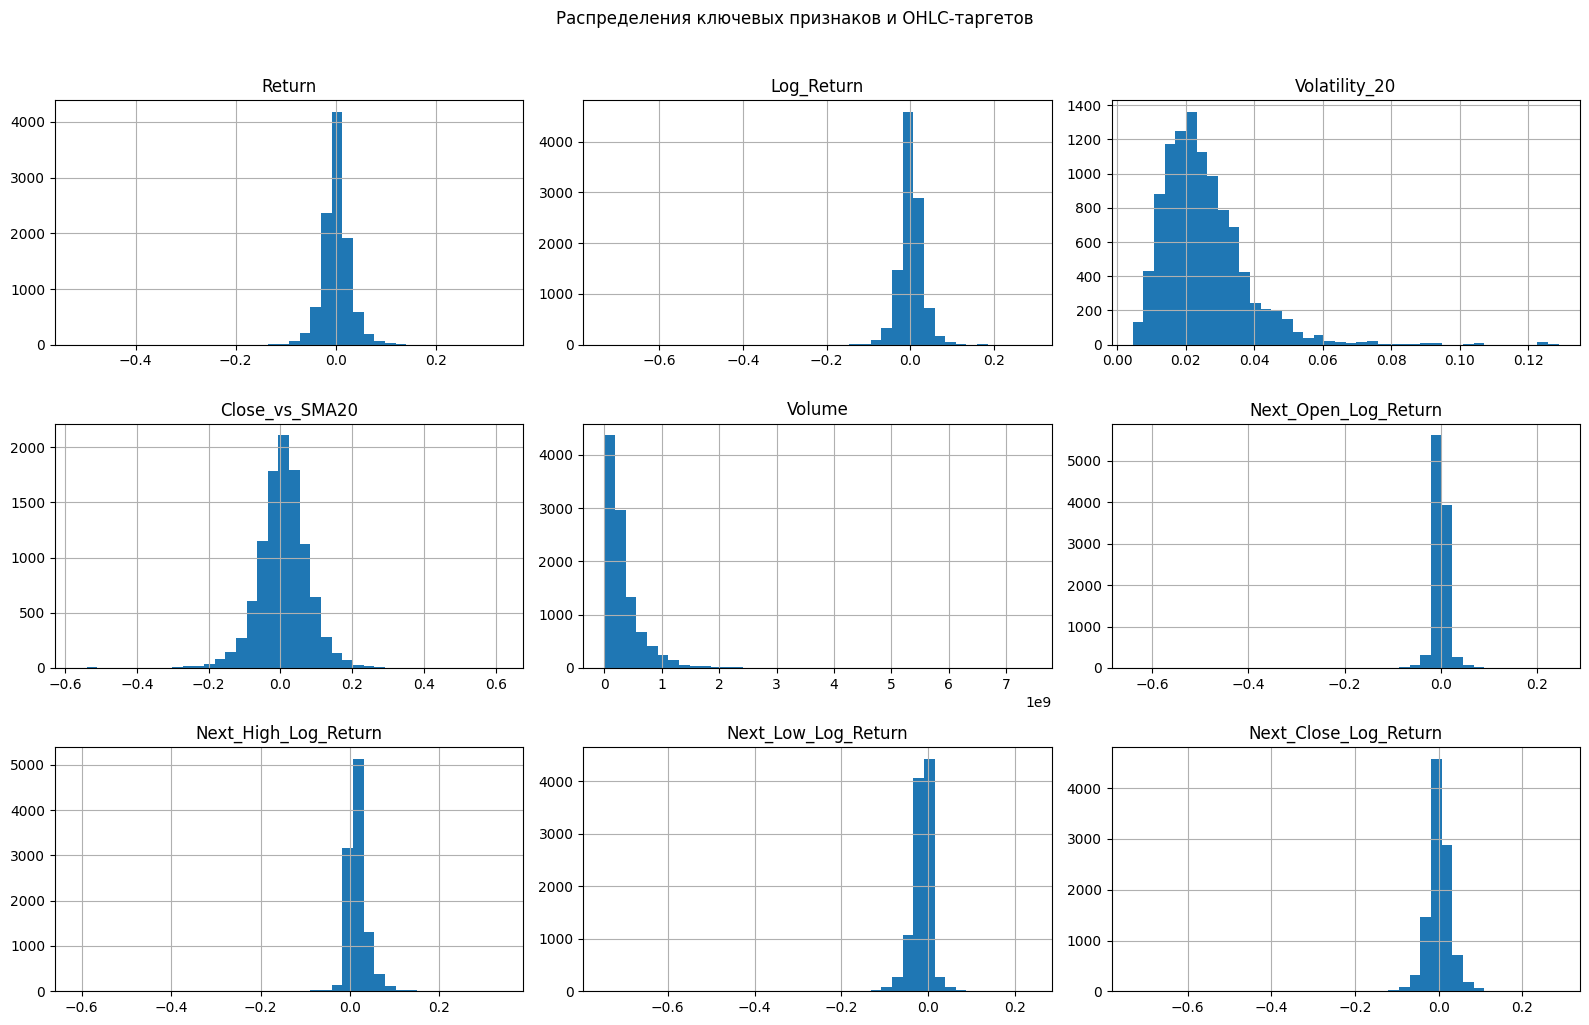

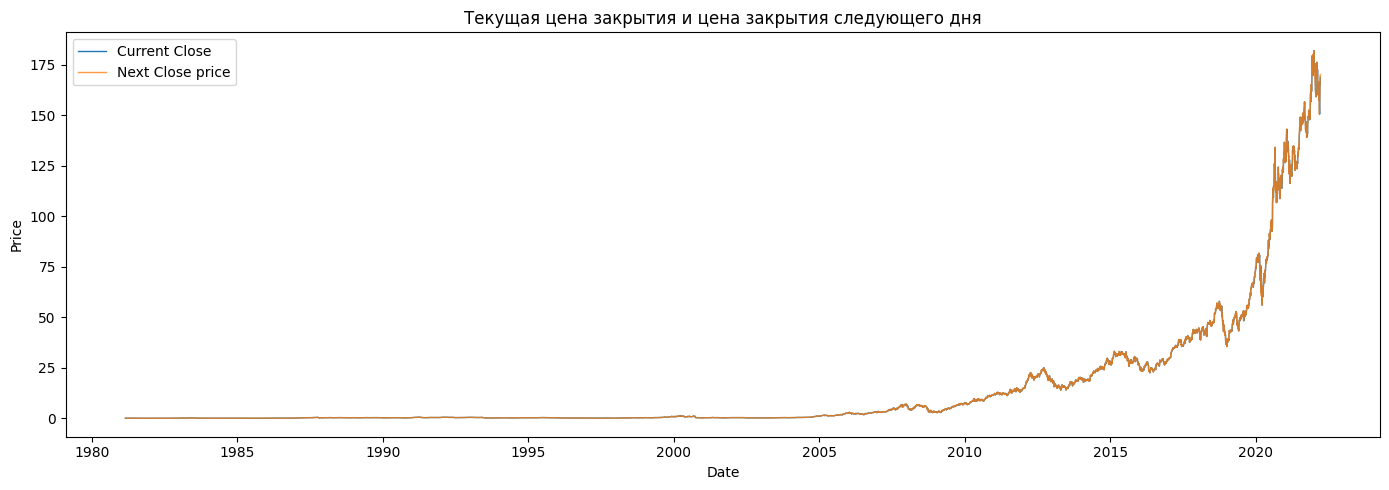

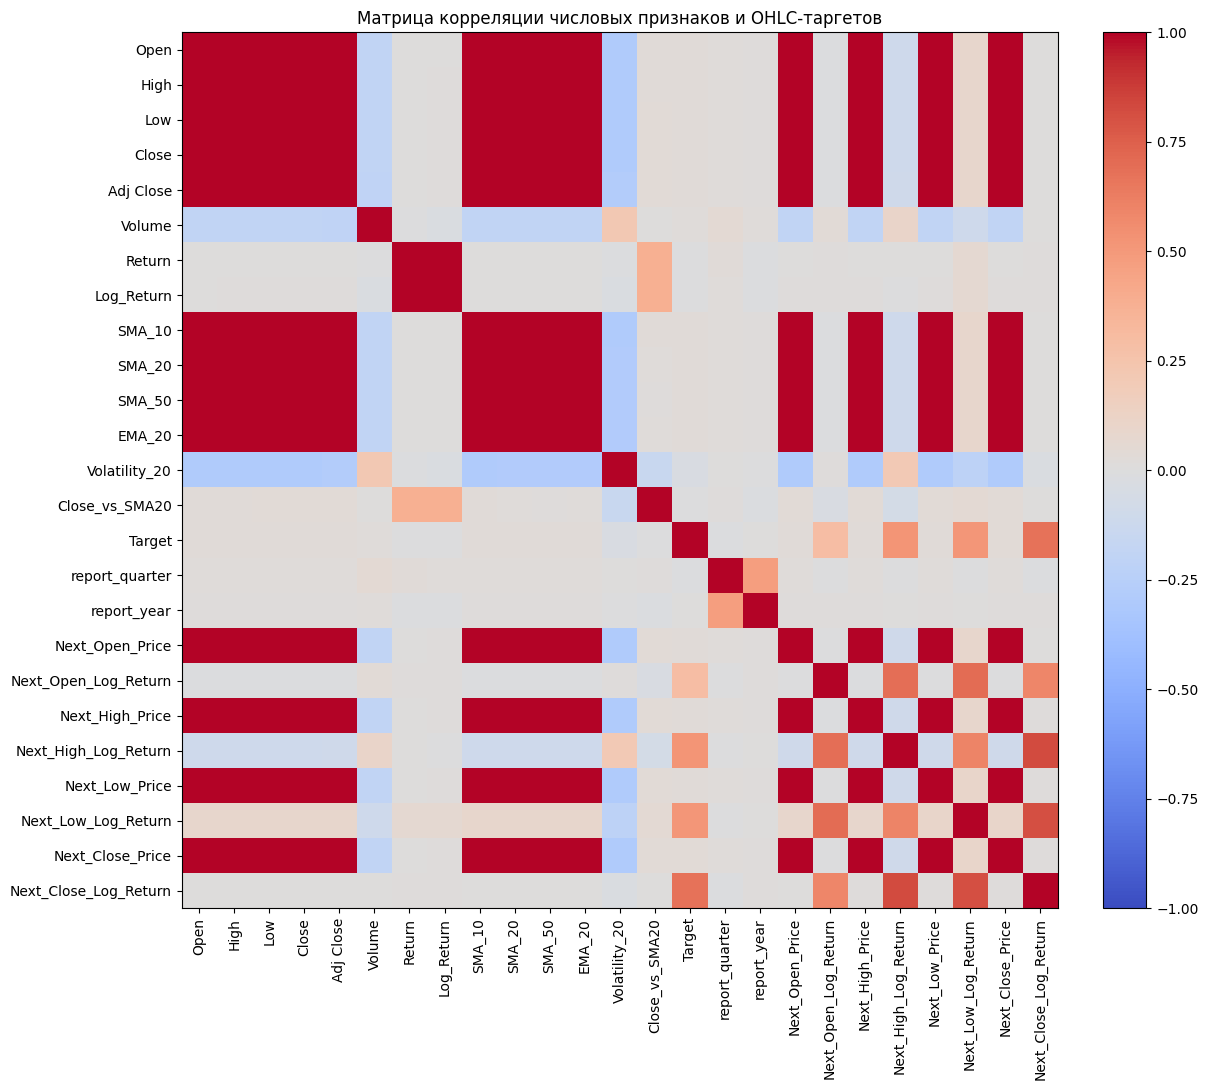

,Next_Open_Log_Return,Next_High_Log_Return,Next_Low_Log_Return,Next_Close_Log_Return
Target,0.289103,0.516047,0.514794,0.676537
Volatility_20,0.012438,0.206145,-0.211767,-0.025158
Log_Return,0.010024,-0.006464,0.061065,0.014169
Return,0.013852,0.000536,0.056335,0.013341
Next_Close_Price,-0.007505,-0.098855,0.094336,0.010420
report_quarter,-0.000715,-0.000854,-0.003742,-0.008615
Next_Low_Price,-0.007619,-0.100538,0.094503,0.008605
report_year,0.009230,0.003468,0.000764,0.008246
Next_High_Price,-0.007927,-0.099240,0.092332,0.008203
Next_Open_Price,-0.007384,-0.100882,0.092250,0.006852


In [13]:
key_numeric_features = ['Return', 'Log_Return', 'Volatility_20', 'Close_vs_SMA20', 'Volume']

reg_df[key_numeric_features + target_cols].hist(bins=40, figsize=(16, 10))
plt.suptitle('Распределения ключевых признаков и OHLC-таргетов', y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plot_dates = reg_df['Date'].to_numpy()
plt.plot(plot_dates, reg_df['Close'].to_numpy(), label='Current Close', linewidth=1)
plt.plot(plot_dates, reg_df['Next_Close_Price'].to_numpy(), label='Next Close price', linewidth=1, alpha=0.8)
plt.title('Текущая цена закрытия и цена закрытия следующего дня')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.tight_layout()
plt.show()

numeric_columns = reg_df.select_dtypes(include=['number', 'bool']).columns
corr_matrix = reg_df[numeric_columns].corr()

plt.figure(figsize=(13, 11))
im = plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)
plt.title('Матрица корреляции числовых признаков и OHLC-таргетов')
plt.tight_layout()
plt.show()

display(corr_matrix[target_cols].drop(index=target_cols, errors='ignore').sort_values('Next_Close_Log_Return', key=lambda s: s.abs(), ascending=False).head(15))

Для регрессии следующего бара таргетами являются логарифмические доходности, а не абсолютные цены. Текущие цены и технические индикаторы могут быть связаны с будущей доходностью, но такая связь обычно слабее, чем корреляция между соседними абсолютными ценами. Поэтому качество модели важно оценивать не только по ошибке лог-доходности, но и после обратного перевода прогноза в OHLC-бар.

## Подготовка признаков и временное разделение

Для временного ряда нельзя случайно перемешивать наблюдения, иначе в обучение попадет информация из будущего. Поэтому делим выборку по времени: первые 80% наблюдений используем для обучения, последние 20% — для тестирования.

`Date`, старый бинарный `Target` и новые `Next_*`-таргеты исключаем из признаков. Категориальные признаки `Day_of_Week` и `Month` кодируем через one-hot encoding, числовые признаки масштабируем, а `report_quarter` и `report_year` оставляем как бинарные индикаторы. Для TCN дополнительно формируем окна последних `lookback` торговых дней.

In [14]:
# Устанавливаем scikit-learn именно в текущий Jupyter kernel, если пакет недоступен
import sys
import subprocess
import importlib.util

if importlib.util.find_spec('sklearn') is None:
    print('scikit-learn не найден в текущем kernel. Устанавливаю...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'scikit-learn'])
    print('Готово. После установки перезапустите эту ячейку и продолжайте выполнение ноутбука.')
else:
    print('scikit-learn доступен в текущем kernel.')

scikit-learn доступен в текущем kernel.


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

feature_exclude_cols = ['Date'] + target_cols + next_price_cols
if 'Target' in reg_df.columns:
    feature_exclude_cols.append('Target')

X_tabular = reg_df.drop(columns=feature_exclude_cols)
y_ohlc = reg_df[target_cols].copy()

categorical_features = ['Day_of_Week', 'Month']
binary_features = ['report_quarter', 'report_year']
numeric_features = [
    col for col in X_tabular.columns
    if col not in categorical_features + binary_features
]

try:
    one_hot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    one_hot_encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)

feature_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', one_hot_encoder, categorical_features),
        ('bin', 'passthrough', binary_features),
    ],
    remainder='drop'
)

target_scaler = StandardScaler()

split_idx = int(len(reg_df) * 0.8)
X_train_tab = X_tabular.iloc[:split_idx]
X_test_tab = X_tabular.iloc[split_idx:]
y_train = y_ohlc.iloc[:split_idx]
y_test = y_ohlc.iloc[split_idx:]

X_train_scaled = feature_preprocessor.fit_transform(X_train_tab)
X_all_scaled = feature_preprocessor.transform(X_tabular)
y_train_scaled = target_scaler.fit_transform(y_train)
y_all_scaled = target_scaler.transform(y_ohlc)

# Небольшое окно снижает расход памяти и ускоряет TCN в локальном окружении.
lookback = 10


def make_windows(features, targets, lookback):
    X_windows, y_windows, row_indices = [], [], []
    features = np.asarray(features, dtype=np.float32)
    targets = np.asarray(targets, dtype=np.float32)
    for end_idx in range(lookback - 1, len(features)):
        start_idx = end_idx - lookback + 1
        X_windows.append(features[start_idx:end_idx + 1])
        y_windows.append(targets[end_idx])
        row_indices.append(end_idx)
    return (
        np.asarray(X_windows, dtype=np.float32),
        np.asarray(y_windows, dtype=np.float32),
        np.asarray(row_indices),
    )

X_seq_all, y_seq_all, seq_row_idx = make_windows(X_all_scaled, y_all_scaled, lookback)
train_seq_mask = seq_row_idx < split_idx
test_seq_mask = seq_row_idx >= split_idx

X_seq_train = X_seq_all[train_seq_mask]
y_seq_train = y_seq_all[train_seq_mask]
X_seq_test = X_seq_all[test_seq_mask]
y_seq_test_scaled = y_seq_all[test_seq_mask]
y_seq_test = target_scaler.inverse_transform(y_seq_test_scaled)
seq_test_dates = reg_df['Date'].iloc[seq_row_idx[test_seq_mask]].reset_index(drop=True)
seq_test_base_close = reg_df['Close'].iloc[seq_row_idx[test_seq_mask]].to_numpy()

# Для локального запуска ограничиваем TCN последними окнами train-части.
# Это сохраняет временную логику и не перегружает TensorFlow.
max_train_windows = 2500
X_seq_train_fit = X_seq_train[-max_train_windows:]
y_seq_train_fit = y_seq_train[-max_train_windows:]
val_size = max(1, int(len(X_seq_train_fit) * 0.2))
X_tcn_train = X_seq_train_fit[:-val_size]
y_tcn_train = y_seq_train_fit[:-val_size]
X_tcn_val = X_seq_train_fit[-val_size:]
y_tcn_val = y_seq_train_fit[-val_size:]

print('Train period:', reg_df['Date'].iloc[0].date(), '-', reg_df['Date'].iloc[split_idx - 1].date())
print('Test period:', reg_df['Date'].iloc[split_idx].date(), '-', reg_df['Date'].iloc[-1].date())
print('Tabular train:', X_train_tab.shape)
print('Tabular test:', X_test_tab.shape)
print('TCN train windows:', X_seq_train.shape)
print('TCN test windows:', X_seq_test.shape)
print('Number of transformed features:', X_all_scaled.shape[1])

Train period: 1981-02-24 - 2013-12-27
Test period: 2013-12-30 - 2022-03-22
Tabular train: (8286, 18)
Tabular test: (2072, 18)
TCN train windows: (8277, 10, 33)
TCN test windows: (2072, 10, 33)
Number of transformed features: 33


## Метрики качества прогноза бара

Для оценки используем классические регрессионные метрики и метрики пересечения прогнозного бара с реальным. Реальный и прогнозный бары рассматриваем как ценовые интервалы `[Low, High]`. Чем больше пересечение этих интервалов, тем лучше модель попала в диапазон следующего дня.

Классический `mAP` из object detection требует confidence score и ранжирования объектов. Здесь используем адаптированный `mAP-like`: среднюю долю прогнозов, где `IoU` выше набора порогов от `0.50` до `0.95`.

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error


def returns_to_prices(base_close, log_returns):
    """Восстанавливает OHLC-цены следующего бара из лог-доходностей относительно текущего Close."""
    base_close = np.asarray(base_close).reshape(-1, 1)
    return base_close * np.exp(np.asarray(log_returns))


def postprocess_ohlc_prices(pred_prices):
    """Исправляет прогноз так, чтобы High был максимумом бара, а Low минимумом."""
    pred_prices = np.asarray(pred_prices).copy()
    open_pred = pred_prices[:, 0]
    close_pred = pred_prices[:, 3]
    high_pred = np.max(pred_prices, axis=1)
    low_pred = np.min(pred_prices, axis=1)
    return np.column_stack([open_pred, high_pred, low_pred, close_pred])


def bar_iou(y_true_prices, y_pred_prices):
    true_low = y_true_prices[:, 2]
    true_high = y_true_prices[:, 1]
    pred_low = y_pred_prices[:, 2]
    pred_high = y_pred_prices[:, 1]

    intersection = np.maximum(0, np.minimum(true_high, pred_high) - np.maximum(true_low, pred_low))
    union = np.maximum(true_high, pred_high) - np.minimum(true_low, pred_low)
    return np.divide(intersection, union, out=np.zeros_like(intersection, dtype=float), where=union > 0)


def smape(y_true, y_pred):
    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2
    return np.mean(np.divide(np.abs(y_true - y_pred), denominator, out=np.zeros_like(y_true, dtype=float), where=denominator != 0)) * 100


def evaluate_ohlc_forecast(model_name, y_true_returns, y_pred_returns, base_close):
    y_true_returns = np.asarray(y_true_returns)
    y_pred_returns = np.asarray(y_pred_returns)

    y_true_prices = returns_to_prices(base_close, y_true_returns)
    y_pred_prices = postprocess_ohlc_prices(returns_to_prices(base_close, y_pred_returns))

    iou_values = bar_iou(y_true_prices, y_pred_prices)
    thresholds = np.arange(0.50, 1.00, 0.05)

    result = {
        'model': model_name,
        'MAE_log_return_mean': mean_absolute_error(y_true_returns, y_pred_returns),
        'RMSE_log_return_mean': np.sqrt(mean_squared_error(y_true_returns, y_pred_returns)),
        'MAE_price_mean': mean_absolute_error(y_true_prices, y_pred_prices),
        'RMSE_price_mean': np.sqrt(mean_squared_error(y_true_prices, y_pred_prices)),
        'sMAPE_price_mean_%': smape(y_true_prices, y_pred_prices),
        'Bar_IoU_mean': iou_values.mean(),
        'IoU@0.50': (iou_values >= 0.50).mean(),
        'IoU@0.70': (iou_values >= 0.70).mean(),
        'IoU@0.90': (iou_values >= 0.90).mean(),
        'mAP_like_0.50_0.95': np.mean([(iou_values >= threshold).mean() for threshold in thresholds]),
    }

    for idx, col in enumerate(target_cols):
        result[f'MAE_{col}'] = mean_absolute_error(y_true_returns[:, idx], y_pred_returns[:, idx])
        result[f'RMSE_{col}'] = np.sqrt(mean_squared_error(y_true_returns[:, idx], y_pred_returns[:, idx]))

    return result, y_pred_prices, iou_values

## Baseline и классические регрессионные модели

Перед TCN сравним несколько простых решений. Наивный baseline прогнозирует следующий бар равным текущему бару. Это сильный baseline для ценовых рядов, потому что дневные цены обычно меняются плавно. Затем обучим Ridge-регрессию и Random Forest для multi-output прогноза `Open`, `High`, `Low`, `Close`.

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

regression_results = []
predictions_by_model = {}
iou_by_model = {}

# Сравниваем модели на одной и той же test-части после split_idx.
y_test_values = y_test.values
test_base_close = X_test_tab['Close'].to_numpy()

# Наивный прогноз: следующий бар равен текущему бару.
# Так как таргеты теперь лог-доходности относительно Close, переводим текущий OHLC в log(OHLC / Close).
naive_pred = np.log(X_test_tab[current_ohlc_cols].div(X_test_tab['Close'], axis=0)).values
naive_result, naive_pred_processed, naive_iou = evaluate_ohlc_forecast('Naive current OHLC', y_test_values, naive_pred, test_base_close)
regression_results.append(naive_result)
predictions_by_model['Naive current OHLC'] = naive_pred_processed
iou_by_model['Naive current OHLC'] = naive_iou

ridge_model = Pipeline(steps=[
    ('preprocessor', feature_preprocessor),
    ('model', Ridge(alpha=1.0)),
])
ridge_model.fit(X_train_tab, y_train)
ridge_pred = ridge_model.predict(X_test_tab)
ridge_result, ridge_pred_processed, ridge_iou = evaluate_ohlc_forecast('Ridge Regression', y_test_values, ridge_pred, test_base_close)
regression_results.append(ridge_result)
predictions_by_model['Ridge Regression'] = ridge_pred_processed
iou_by_model['Ridge Regression'] = ridge_iou

rf_model = Pipeline(steps=[
    ('preprocessor', feature_preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    )),
])
rf_model.fit(X_train_tab, y_train)
rf_pred = rf_model.predict(X_test_tab)
rf_result, rf_pred_processed, rf_iou = evaluate_ohlc_forecast('Random Forest Regressor', y_test_values, rf_pred, test_base_close)
regression_results.append(rf_result)
predictions_by_model['Random Forest Regressor'] = rf_pred_processed
iou_by_model['Random Forest Regressor'] = rf_iou

metrics_df = pd.DataFrame(regression_results).sort_values('MAE_log_return_mean').reset_index(drop=True)
display(metrics_df)

,model,MAE_log_return_mean,RMSE_log_return_mean,MAE_price_mean,RMSE_price_mean,sMAPE_price_mean_%,Bar_IoU_mean,IoU@0.50,IoU@0.70,IoU@0.90,mAP_like_0.50_0.95,MAE_Next_Open_Log_Return,RMSE_Next_Open_Log_Return,MAE_Next_High_Log_Return,RMSE_Next_High_Log_Return,MAE_Next_Low_Log_Return,RMSE_Next_Low_Log_Return,MAE_Next_Close_Log_Return,RMSE_Next_Close_Log_Return
0,Random Forest Regressor,0.009834,0.014846,0.624296,1.127777,0.983306,0.427988,0.401062,0.125000,0.010135,0.142664,0.006949,0.012028,0.008918,0.013358,0.010870,0.015308,0.012598,0.018005
1,Naive current OHLC,0.011710,0.017122,0.752775,1.344881,1.170919,0.369315,0.326255,0.118243,0.008687,0.123890,0.012697,0.018567,0.010224,0.014978,0.011656,0.016876,0.012264,0.017855
2,Ridge Regression,0.015887,0.023394,1.210826,2.447934,1.453666,0.348373,0.278475,0.088803,0.007722,0.102220,0.008588,0.013572,0.015771,0.022179,0.017118,0.024137,0.022070,0.030502


## TCN: Temporal Convolutional Network

TCN работает не с одной строкой, а с окном последних `lookback` дней. Внутри используются causal dilated convolutions: модель видит только прошлые значения и постепенно расширяет receptive field за счет dilation rates. На выходе получаем четыре числа: прогноз логарифмических доходностей `Next_Open`, `Next_High`, `Next_Low`, `Next_Close` относительно текущего `Close`.

In [18]:
import gc
import os
import time
import importlib.util

# TensorFlow GPU в текущем Windows-окружении подвисает на cuDNN.
# Для стабильности принудительно запускаем TCN на CPU.
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

tensorflow_available = importlib.util.find_spec('tensorflow') is not None

if not tensorflow_available:
    print('TensorFlow не установлен в текущем Jupyter kernel.')
    print('TCN не будет обучена в этом запуске, но baseline-модели выше уже можно оценивать.')
    print('Чтобы запустить TCN, переключите kernel на Python 3.8, где TensorFlow доступен, или установите TensorFlow в совместимое окружение.')
    metrics_df = pd.DataFrame(regression_results).sort_values('MAE_log_return_mean').reset_index(drop=True)
    display(metrics_df)
else:
    import tensorflow as tf
    from tensorflow.keras import layers, models, callbacks

    tf.keras.backend.clear_session()
    gc.collect()

    try:
        tf.config.set_visible_devices([], 'GPU')
        print('TensorFlow GPU disabled: training TCN on CPU')
    except RuntimeError:
        print('GPU уже был инициализирован. Сделайте Restart Kernel, чтобы CPU-only режим применился корректно.')

    try:
        # Ограничиваем число потоков, чтобы TensorFlow не подвешивал локальное окружение.
        tf.config.threading.set_intra_op_parallelism_threads(2)
        tf.config.threading.set_inter_op_parallelism_threads(2)
    except RuntimeError:
        print('Потоки TensorFlow уже инициализированы. Если обучение зависает, сделайте Restart Kernel и запустите ноутбук заново.')

    tf.random.set_seed(42)
    np.random.seed(42)

    def residual_tcn_block(x, filters, kernel_size, dilation_rate, dropout_rate):
        shortcut = x

        x = layers.Conv1D(
            filters=filters,
            kernel_size=kernel_size,
            padding='causal',
            dilation_rate=dilation_rate,
            activation='relu',
        )(x)
        x = layers.LayerNormalization()(x)
        x = layers.Dropout(dropout_rate)(x)

        x = layers.Conv1D(
            filters=filters,
            kernel_size=kernel_size,
            padding='causal',
            dilation_rate=dilation_rate,
            activation='relu',
        )(x)
        x = layers.LayerNormalization()(x)

        if shortcut.shape[-1] != filters:
            shortcut = layers.Conv1D(filters=filters, kernel_size=1, padding='same')(shortcut)

        x = layers.Add()([shortcut, x])
        return layers.Activation('relu')(x)

    def build_tcn_model(input_shape, output_dim=4):
        inputs = layers.Input(shape=input_shape)
        x = inputs

        for dilation_rate in [1, 2]:
            x = residual_tcn_block(
                x,
                filters=16,
                kernel_size=3,
                dilation_rate=dilation_rate,
                dropout_rate=0.15,
            )

        x = layers.Lambda(lambda tensor: tensor[:, -1, :])(x)
        x = layers.Dense(16, activation='relu')(x)
        x = layers.Dropout(0.15)(x)
        outputs = layers.Dense(output_dim)(x)

        model = models.Model(inputs=inputs, outputs=outputs)
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
            loss=tf.keras.losses.Huber(),
            metrics=['mae'],
        )
        return model

    tcn_model = build_tcn_model(input_shape=(X_tcn_train.shape[1], X_tcn_train.shape[2]))

    print('X_tcn_train shape:', X_tcn_train.shape)
    print('y_tcn_train shape:', y_tcn_train.shape)
    print('X_tcn_val shape:', X_tcn_val.shape)
    print('y_tcn_val shape:', y_tcn_val.shape)
    print('X_seq_test shape:', X_seq_test.shape)
    print('TCN parameters:', tcn_model.count_params())

    class EpochTimer(callbacks.Callback):
        def on_train_begin(self, logs=None):
            self.train_start = time.time()
            self.total_batches = int(np.ceil(len(X_tcn_train) / 8))
            print('TCN training started')
            print(f'Train batches per epoch: {self.total_batches}')

        def on_epoch_begin(self, epoch, logs=None):
            self.epoch_start = time.time()
            self.current_epoch = epoch + 1
            print(f'Epoch {self.current_epoch} started')

        def on_train_batch_end(self, batch, logs=None):
            # Печатаем прогресс не на каждом батче, чтобы не перегружать notebook.
            if (batch + 1) % 20 == 0 or (batch + 1) == self.total_batches:
                logs = logs or {}
                epoch_elapsed = time.time() - self.epoch_start
                print(
                    f"Epoch {self.current_epoch}: batch {batch + 1}/{self.total_batches} | "
                    f"loss={logs.get('loss', float('nan')):.6f} | "
                    f"elapsed={epoch_elapsed:.1f}s"
                )

        def on_epoch_end(self, epoch, logs=None):
            logs = logs or {}
            epoch_elapsed = time.time() - self.epoch_start
            total_elapsed = time.time() - self.train_start
            print(
                f"Epoch {epoch + 1} finished in {epoch_elapsed:.1f}s | "
                f"loss={logs.get('loss', float('nan')):.6f} | "
                f"val_loss={logs.get('val_loss', float('nan')):.6f} | "
                f"total={total_elapsed:.1f}s"
            )

    early_stopping = callbacks.EarlyStopping(
        monitor='val_loss',
        patience=2,
        restore_best_weights=True,
    )

    history = tcn_model.fit(
        X_tcn_train,
        y_tcn_train,
        epochs=8,
        batch_size=8,
        validation_data=(X_tcn_val, y_tcn_val),
        shuffle=False,
        callbacks=[early_stopping, EpochTimer()],
        verbose=0,
    )

    tcn_pred_scaled = tcn_model.predict(X_seq_test)
    tcn_pred = target_scaler.inverse_transform(tcn_pred_scaled)
    tcn_result, tcn_pred_processed, tcn_iou = evaluate_ohlc_forecast('TCN', y_seq_test, tcn_pred, seq_test_base_close)

    regression_results.append(tcn_result)
    predictions_by_model['TCN'] = tcn_pred_processed
    iou_by_model['TCN'] = tcn_iou

    metrics_df = pd.DataFrame(regression_results).sort_values('MAE_log_return_mean').reset_index(drop=True)
    display(metrics_df)

TensorFlow GPU disabled: training TCN on CPU
X_tcn_train shape: (2000, 10, 33)
y_tcn_train shape: (2000, 4)
X_tcn_val shape: (500, 10, 33)
y_tcn_val shape: (500, 4)
X_seq_test shape: (2072, 10, 33)
TCN parameters: 4964
TCN training started
Train batches per epoch: 250
Epoch 1 started
Epoch 1: batch 20/250 | loss=0.549417 | elapsed=1.2s
Epoch 1: batch 40/250 | loss=0.482473 | elapsed=1.2s
Epoch 1: batch 60/250 | loss=0.422306 | elapsed=1.2s
Epoch 1: batch 80/250 | loss=0.389777 | elapsed=1.3s
Epoch 1: batch 100/250 | loss=0.354339 | elapsed=1.3s
Epoch 1: batch 120/250 | loss=0.348921 | elapsed=1.4s
Epoch 1: batch 140/250 | loss=0.346706 | elapsed=1.4s
Epoch 1: batch 160/250 | loss=0.377643 | elapsed=1.5s
Epoch 1: batch 180/250 | loss=0.358323 | elapsed=1.5s
Epoch 1: batch 200/250 | loss=0.342810 | elapsed=1.6s
Epoch 1: batch 220/250 | loss=0.323915 | elapsed=1.6s
Epoch 1: batch 240/250 | loss=0.308480 | elapsed=1.7s
Epoch 1: batch 250/250 | loss=0.302571 | elapsed=1.7s
Epoch 1 finished 

,model,MAE_log_return_mean,RMSE_log_return_mean,MAE_price_mean,RMSE_price_mean,sMAPE_price_mean_%,Bar_IoU_mean,IoU@0.50,IoU@0.70,IoU@0.90,mAP_like_0.50_0.95,MAE_Next_Open_Log_Return,RMSE_Next_Open_Log_Return,MAE_Next_High_Log_Return,RMSE_Next_High_Log_Return,MAE_Next_Low_Log_Return,RMSE_Next_Low_Log_Return,MAE_Next_Close_Log_Return,RMSE_Next_Close_Log_Return
0,Random Forest Regressor,0.009834,0.014846,0.624296,1.127777,0.983306,0.427988,0.401062,0.125000,0.010135,0.142664,0.006949,0.012028,0.008918,0.013358,0.010870,0.015308,0.012598,0.018005
1,Naive current OHLC,0.011710,0.017122,0.752775,1.344881,1.170919,0.369315,0.326255,0.118243,0.008687,0.123890,0.012697,0.018567,0.010224,0.014978,0.011656,0.016876,0.012264,0.017855
2,TCN,0.014657,0.021649,1.276303,2.547842,1.465563,0.374721,0.261100,0.063224,0.005792,0.083977,0.011726,0.017965,0.018481,0.027167,0.015920,0.022117,0.012503,0.018025
3,Ridge Regression,0.015887,0.023394,1.210826,2.447934,1.453666,0.348373,0.278475,0.088803,0.007722,0.102220,0.008588,0.013572,0.015771,0.022179,0.017118,0.024137,0.022070,0.030502


Epoch 2: batch 140/250 | loss=0.238663 | elapsed=0.2s
Epoch 2: batch 160/250 | loss=0.280933 | elapsed=0.2s
Epoch 2: batch 180/250 | loss=0.268950 | elapsed=0.3s
Epoch 2: batch 200/250 | loss=0.260814 | elapsed=0.3s
Epoch 2: batch 220/250 | loss=0.247908 | elapsed=0.3s
Epoch 2: batch 240/250 | loss=0.238287 | elapsed=0.4s
Epoch 2: batch 250/250 | loss=0.234849 | elapsed=0.4s


Epoch 2 finished in 0.5s | loss=0.234849 | val_loss=0.144222 | total=2.0s
Epoch 3 started
Epoch 3: batch 20/250 | loss=0.222514 | elapsed=0.0s
Epoch 3: batch 40/250 | loss=0.251424 | elapsed=0.1s
Epoch 3: batch 60/250 | loss=0.234457 | elapsed=0.1s
Epoch 3: batch 80/250 | loss=0.236930 | elapsed=0.1s
Epoch 3: batch 100/250 | loss=0.219684 | elapsed=0.2s
Epoch 3: batch 120/250 | loss=0.224917 | elapsed=0.2s


Epoch 3: batch 140/250 | loss=0.232689 | elapsed=0.2s
Epoch 3: batch 160/250 | loss=0.276592 | elapsed=0.2s
Epoch 3: batch 180/250 | loss=0.264635 | elapsed=0.3s
Epoch 3: batch 200/250 | loss=0.256752 | elapsed=0.3s
Epoch 3: batch 220/250 | loss=0.244124 | elapsed=0.3s
Epoch 3: batch 240/250 | loss=0.234644 | elapsed=0.4s
Epoch 3: batch 250/250 | loss=0.231433 | elapsed=0.4s


...

Epoch 7: batch 140/250 | loss=0.232419 | elapsed=0.2s
Epoch 7: batch 160/250 | loss=0.273812 | elapsed=0.3s
Epoch 7: batch 180/250 | loss=0.261513 | elapsed=0.3s
Epoch 7: batch 200/250 | loss=0.253717 | elapsed=0.3s
Epoch 7: batch 220/250 | loss=0.241161 | elapsed=0.3s
Epoch 7: batch 240/250 | loss=0.231795 | elapsed=0.4s
Epoch 7: batch 250/250 | loss=0.228538 | elapsed=0.4s


Epoch 7 finished in 0.5s | loss=0.228538 | val_loss=0.140304 | total=4.2s
Epoch 8 started
Epoch 8: batch 20/250 | loss=0.224712 | elapsed=0.0s
Epoch 8: batch 40/250 | loss=0.251988 | elapsed=0.1s
Epoch 8: batch 60/250 | loss=0.234193 | elapsed=0.1s
Epoch 8: batch 80/250 | loss=0.237656 | elapsed=0.1s
Epoch 8: batch 100/250 | loss=0.219632 | elapsed=0.2s
Epoch 8: batch 120/250 | loss=0.224922 | elapsed=0.2s


Epoch 8: batch 140/250 | loss=0.232600 | elapsed=0.2s
Epoch 8: batch 160/250 | loss=0.273717 | elapsed=0.2s
Epoch 8: batch 180/250 | loss=0.261489 | elapsed=0.3s
Epoch 8: batch 200/250 | loss=0.253480 | elapsed=0.3s
Epoch 8: batch 220/250 | loss=0.240714 | elapsed=0.3s
Epoch 8: batch 240/250 | loss=0.231316 | elapsed=0.4s
Epoch 8: batch 250/250 | loss=0.228094 | elapsed=0.4s


Epoch 8 finished in 0.4s | loss=0.228094 | val_loss=0.140282 | total=4.7s


,model,MAE_log_return_mean,RMSE_log_return_mean,MAE_price_mean,RMSE_price_mean,sMAPE_price_mean_%,Bar_IoU_mean,IoU@0.50,IoU@0.70,IoU@0.90,mAP_like_0.50_0.95,MAE_Next_Open_Log_Return,RMSE_Next_Open_Log_Return,MAE_Next_High_Log_Return,RMSE_Next_High_Log_Return,MAE_Next_Low_Log_Return,RMSE_Next_Low_Log_Return,MAE_Next_Close_Log_Return,RMSE_Next_Close_Log_Return
0,Random Forest Regressor,0.009834,0.014846,0.624296,1.127777,0.983306,0.427988,0.401062,0.125000,0.010135,0.142664,0.006949,0.012028,0.008918,0.013358,0.010870,0.015308,0.012598,0.018005
1,Naive current OHLC,0.011710,0.017122,0.752775,1.344881,1.170919,0.369315,0.326255,0.118243,0.008687,0.123890,0.012697,0.018567,0.010224,0.014978,0.011656,0.016876,0.012264,0.017855
2,TCN,0.014657,0.021649,1.276303,2.547842,1.465563,0.374721,0.261100,0.063224,0.005792,0.083977,0.011726,0.017965,0.018481,0.027167,0.015920,0.022117,0.012503,0.018025
3,Ridge Regression,0.015887,0.023394,1.210826,2.447934,1.453666,0.348373,0.278475,0.088803,0.007722,0.102220,0.008588,0.013572,0.015771,0.022179,0.017118,0.024137,0.022070,0.030502


## Визуализация качества прогноза

Сравним модели по таблице метрик и визуально посмотрим, как лучшая модель прогнозирует `Close` и ценовой диапазон `[Low, High]`. Дополнительно построим распределение `IoU`, чтобы увидеть, насколько часто прогнозный бар пересекается с реальным.

Лучшая модель по среднему MAE лог-доходности: Random Forest Regressor


,model,MAE_log_return_mean,RMSE_log_return_mean,MAE_price_mean,RMSE_price_mean,sMAPE_price_mean_%,Bar_IoU_mean,IoU@0.50,IoU@0.70,IoU@0.90,mAP_like_0.50_0.95,MAE_Next_Open_Log_Return,RMSE_Next_Open_Log_Return,MAE_Next_High_Log_Return,RMSE_Next_High_Log_Return,MAE_Next_Low_Log_Return,RMSE_Next_Low_Log_Return,MAE_Next_Close_Log_Return,RMSE_Next_Close_Log_Return
0,Random Forest Regressor,0.009834,0.014846,0.624296,1.127777,0.983306,0.427988,0.401062,0.125000,0.010135,0.142664,0.006949,0.012028,0.008918,0.013358,0.010870,0.015308,0.012598,0.018005
1,Naive current OHLC,0.011710,0.017122,0.752775,1.344881,1.170919,0.369315,0.326255,0.118243,0.008687,0.123890,0.012697,0.018567,0.010224,0.014978,0.011656,0.016876,0.012264,0.017855
2,TCN,0.014657,0.021649,1.276303,2.547842,1.465563,0.374721,0.261100,0.063224,0.005792,0.083977,0.011726,0.017965,0.018481,0.027167,0.015920,0.022117,0.012503,0.018025
3,Ridge Regression,0.015887,0.023394,1.210826,2.447934,1.453666,0.348373,0.278475,0.088803,0.007722,0.102220,0.008588,0.013572,0.015771,0.022179,0.017118,0.024137,0.022070,0.030502


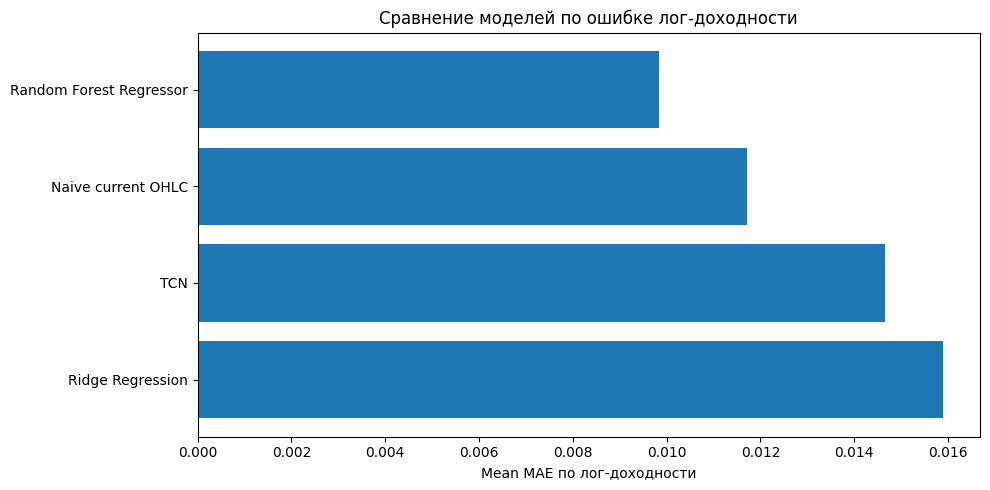

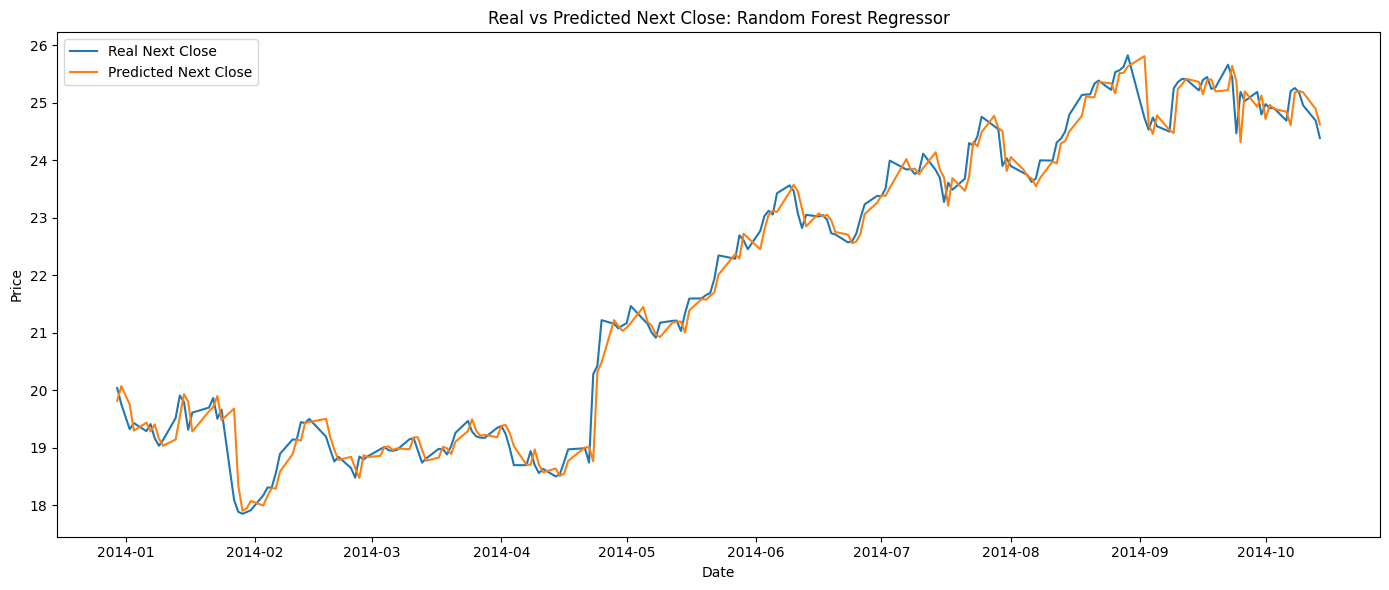

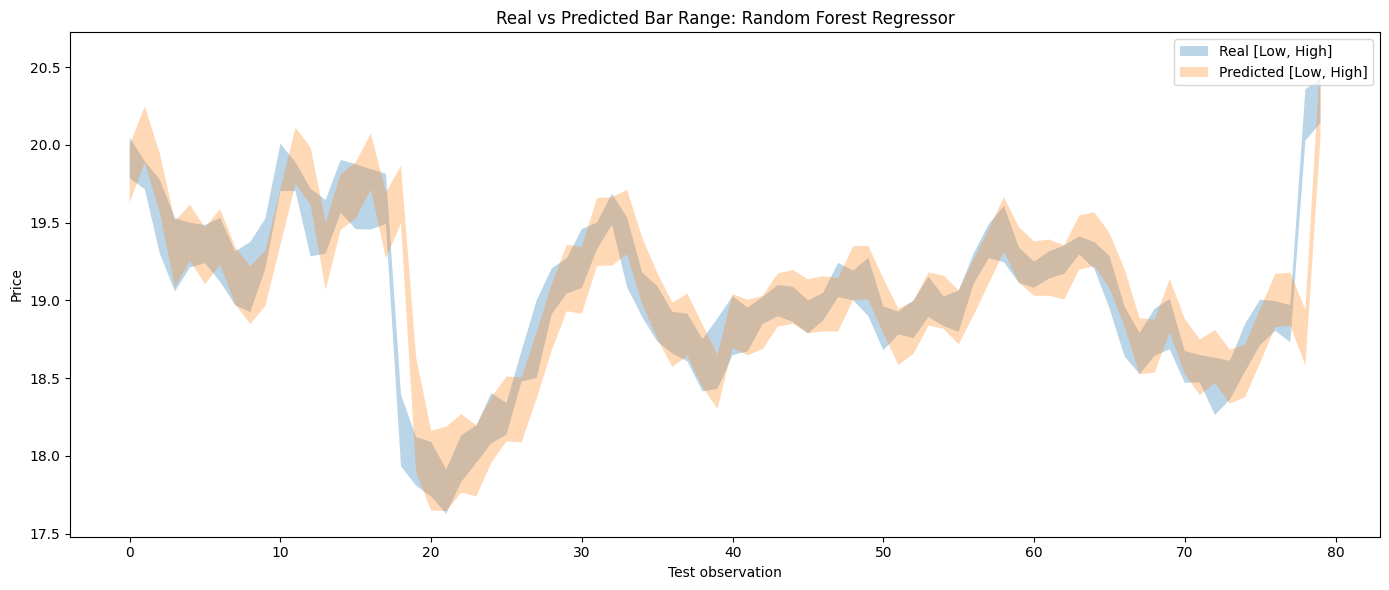

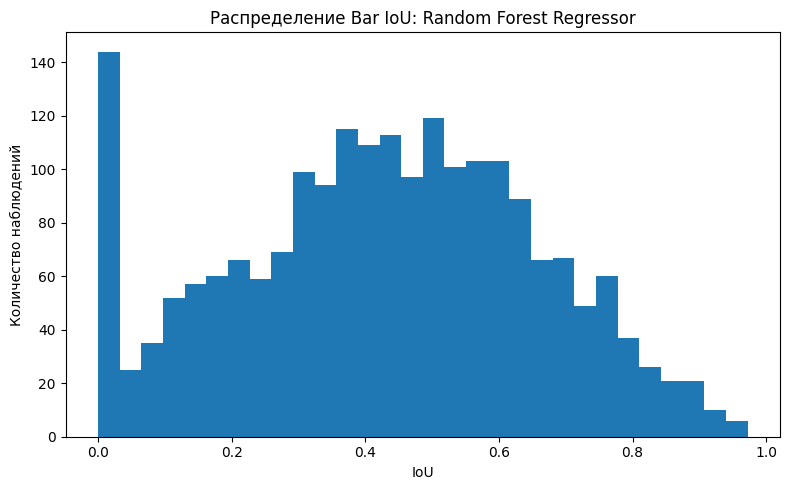

In [19]:
best_regression_model = metrics_df.iloc[0]['model']
best_prediction = predictions_by_model[best_regression_model]
best_iou = iou_by_model[best_regression_model]

print('Лучшая модель по среднему MAE лог-доходности:', best_regression_model)
display(metrics_df)

plt.figure(figsize=(10, 5))
plt.barh(metrics_df['model'], metrics_df['MAE_log_return_mean'])
plt.xlabel('Mean MAE по лог-доходности')
plt.title('Сравнение моделей по ошибке лог-доходности')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Для TCN тестовый y может начинаться с той же test-части, но используем корректные массивы по выбранной модели.
if best_regression_model == 'TCN':
    plot_dates = seq_test_dates
    y_true_plot = returns_to_prices(seq_test_base_close, y_seq_test)
else:
    plot_dates = reg_df['Date'].iloc[split_idx:].reset_index(drop=True)
    y_true_plot = returns_to_prices(test_base_close, y_test_values)

plot_len = min(200, len(plot_dates))

plt.figure(figsize=(14, 6))
plot_dates_np = plot_dates.iloc[:plot_len].to_numpy()
plt.plot(plot_dates_np, y_true_plot[:plot_len, 3], label='Real Next Close', linewidth=1.5)
plt.plot(plot_dates_np, best_prediction[:plot_len, 3], label='Predicted Next Close', linewidth=1.5)
plt.title(f'Real vs Predicted Next Close: {best_regression_model}')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.tight_layout()
plt.show()

interval_len = min(80, len(plot_dates))
x_axis = np.arange(interval_len)

plt.figure(figsize=(14, 6))
plt.fill_between(
    x_axis,
    y_true_plot[:interval_len, 2],
    y_true_plot[:interval_len, 1],
    alpha=0.3,
    label='Real [Low, High]',
)
plt.fill_between(
    x_axis,
    best_prediction[:interval_len, 2],
    best_prediction[:interval_len, 1],
    alpha=0.3,
    label='Predicted [Low, High]',
)
plt.title(f'Real vs Predicted Bar Range: {best_regression_model}')
plt.xlabel('Test observation')
plt.ylabel('Price')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(best_iou, bins=30)
plt.title(f'Распределение Bar IoU: {best_regression_model}')
plt.xlabel('IoU')
plt.ylabel('Количество наблюдений')
plt.tight_layout()
plt.show()

## Итоговые выводы

В проекте задача была переформулирована как регрессия логарифмических доходностей следующего OHLC-бара акции Apple. Модель прогнозирует сразу четыре значения: `log(Next_Open / Close)`, `log(Next_High / Close)`, `log(Next_Low / Close)`, `log(Next_Close / Close)`.

Для оценки качества используются ошибки по лог-доходностям, а также метрики после обратного восстановления OHLC-цен: `MAE_price`, `RMSE_price`, `sMAPE_price`, средний `Bar IoU`, `IoU@0.50`, `IoU@0.70`, `IoU@0.90` и `mAP-like` по набору IoU-порогов. Это позволяет оценивать модель и как финансовый прогноз доходности, и как прогноз формы следующего бара.

В качестве моделей сравниваются наивный прогноз текущим баром, классические регрессионные модели и нейросетевая TCN. При интерпретации результатов важно учитывать, что даже хороший прогноз бара не является готовой торговой стратегией: здесь не учитываются комиссии, спреды, проскальзывание, ликвидность, новости и изменение рыночного режима.